Group A (Novice + 3 summative years):       30,779 students
Group B (Intermediate + 3 summative years): 4,441 students

Enrollment files loaded:
  2021-22: 1,519,618 rows
  2022-23: 1,467,738 rows
  2023-24: 1,471,765 rows

Group A enrollment records: 30,779
Group B enrollment records: 4,441


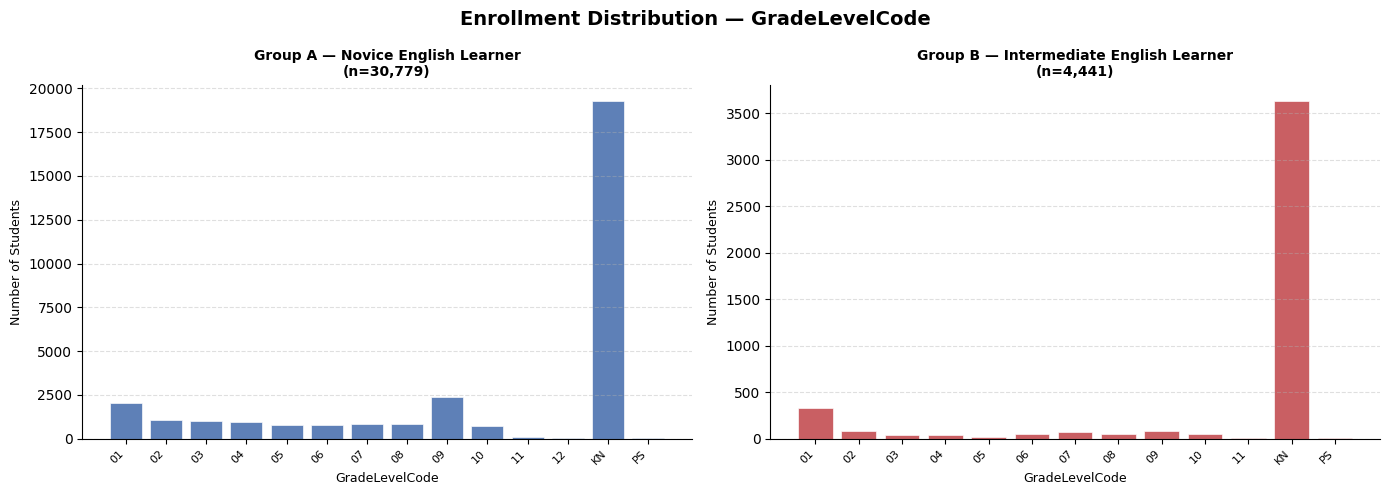

Saved: group_ab_GradeLevelCode.png


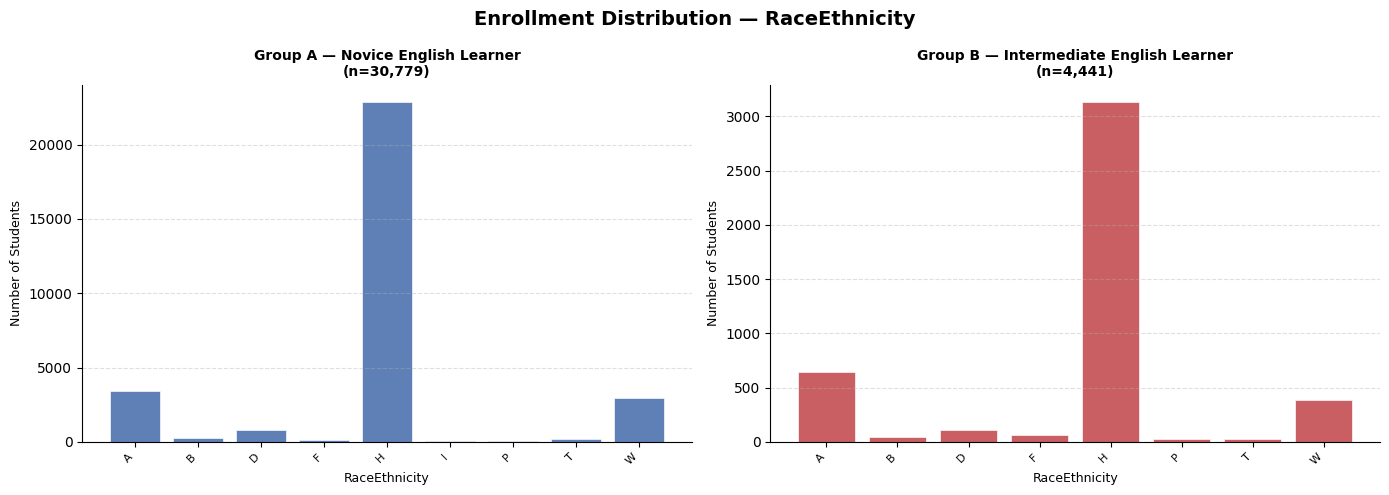

Saved: group_ab_RaceEthnicity.png


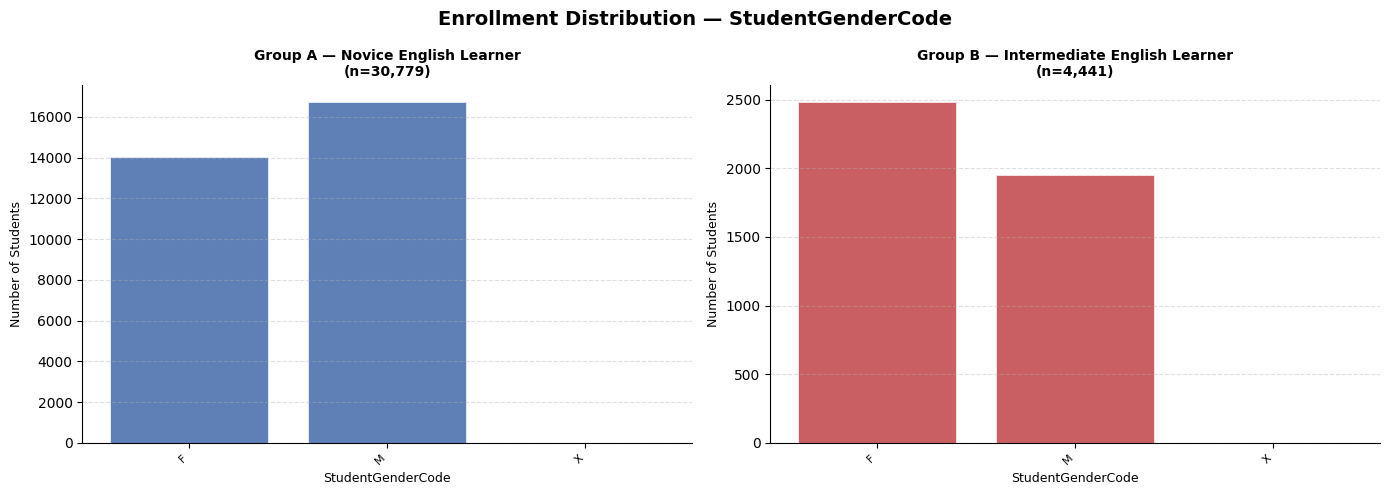

Saved: group_ab_StudentGenderCode.png


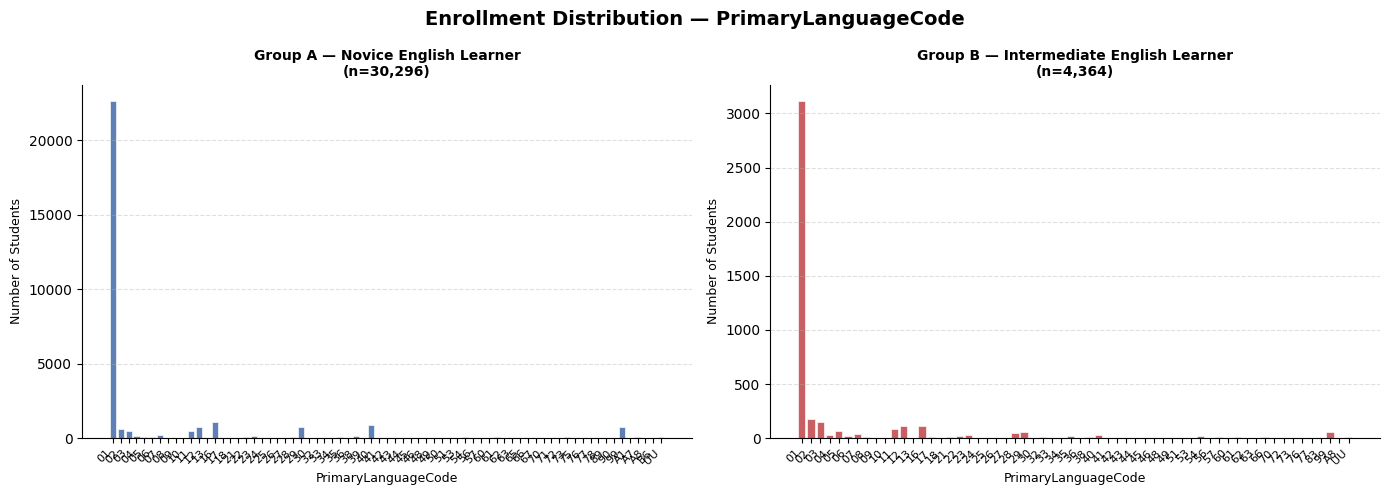

Saved: group_ab_PrimaryLanguageCode.png


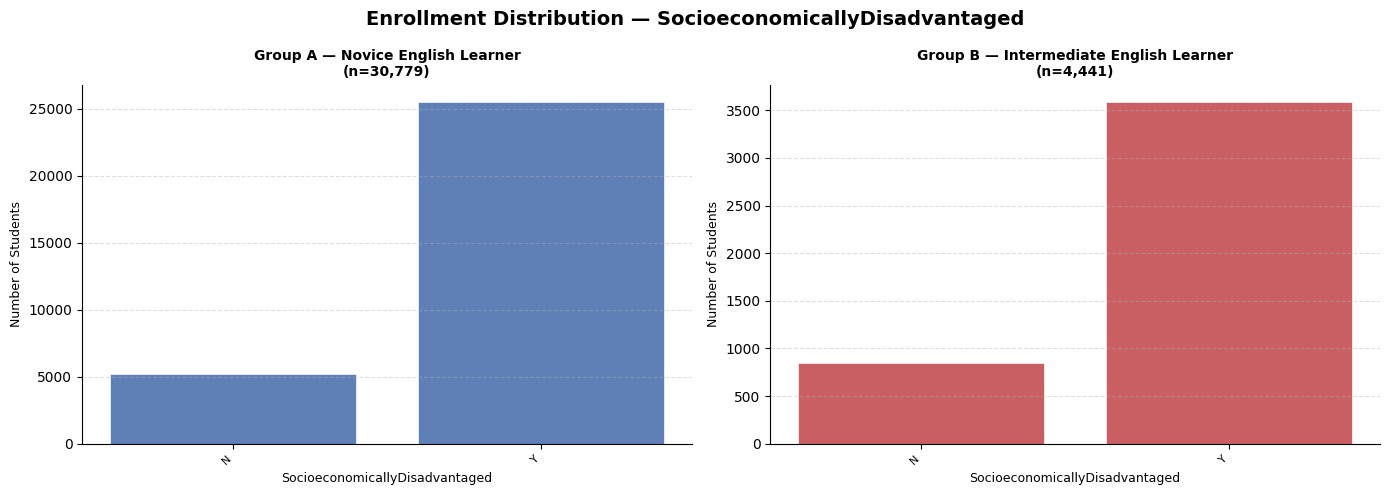

Saved: group_ab_SocioeconomicallyDisadvantaged.png


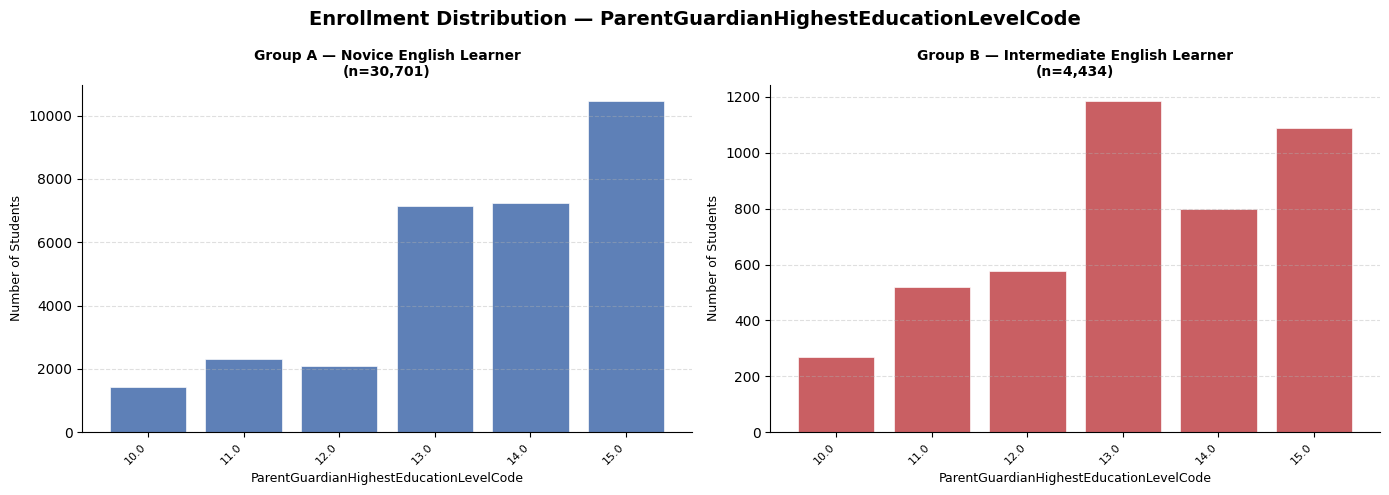

Saved: group_ab_ParentGuardianHighestEducationLevelCode.png


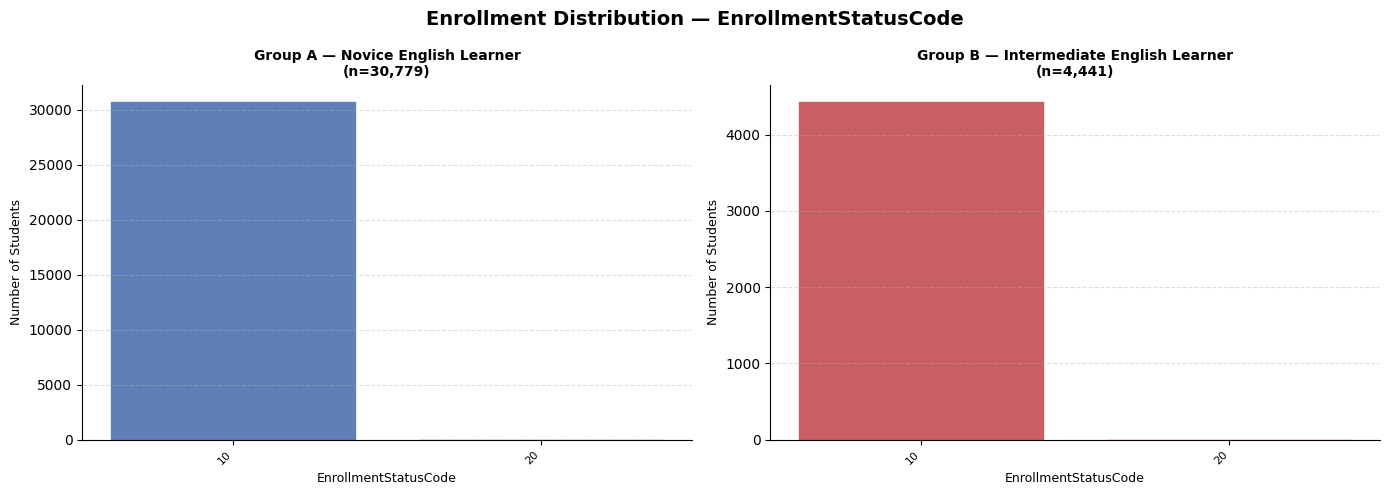

Saved: group_ab_EnrollmentStatusCode.png


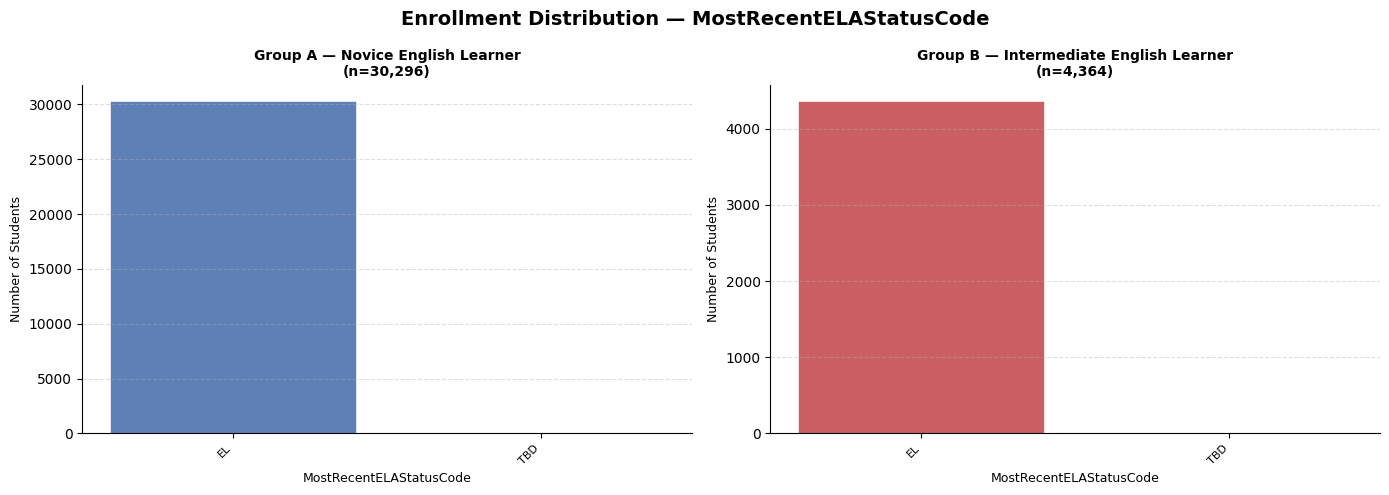

Saved: group_ab_MostRecentELAStatusCode.png


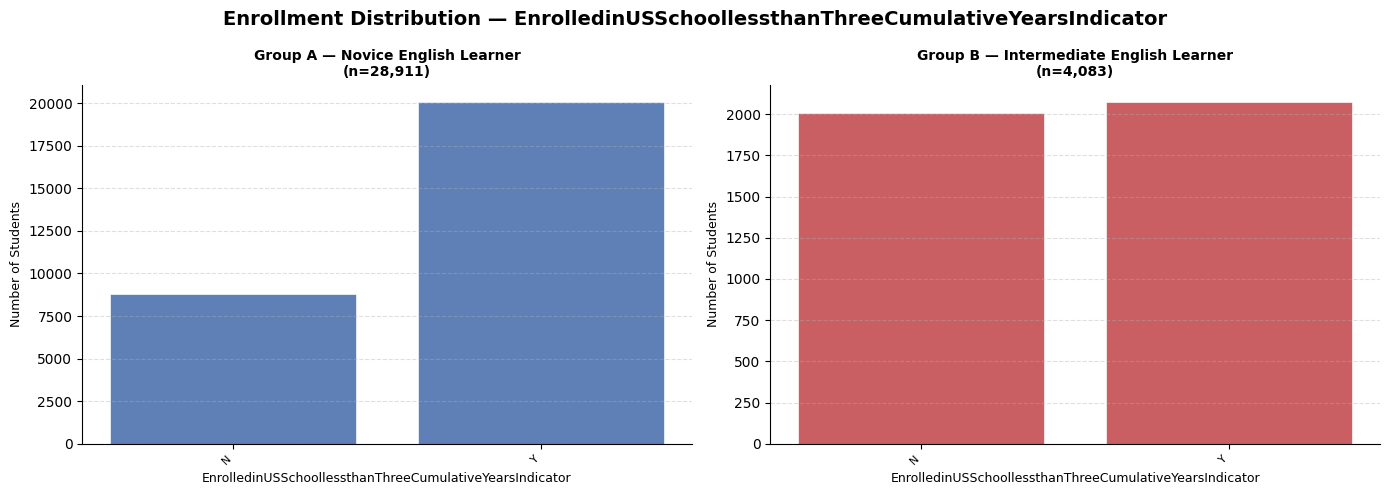

Saved: group_ab_EnrolledinUSSchoollessthanThreeCumulativeYearsIndicator.png


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# --- Paths ---
enrollment_dir = "../1095 Data/Enrollment"  # Update if needed

# --- Load Group A and Group B SSIDs from CSV ---
group_a_ssids = set(pd.read_csv("group_a_ssids.csv")["SSID"])
group_b_ssids = set(pd.read_csv("group_b_ssids.csv")["SSID"])

print(f"Group A (Novice + 3 summative years):       {len(group_a_ssids):,} students")
print(f"Group B (Intermediate + 3 summative years): {len(group_b_ssids):,} students")

# --- Load Enrollment files ---
enrollment_files = {
    "2021-22": "CEnrollment_21-22.csv",
    "2022-23": "CEnrollment_22-23.csv",
    "2023-24": "CEnrollment_23-24.csv",
}

enrollments = {}
for label, filename in enrollment_files.items():
    enrollments[label] = pd.read_csv(os.path.join(enrollment_dir, filename), low_memory=False)

print("\nEnrollment files loaded:")
for label, df in enrollments.items():
    print(f"  {label}: {len(df):,} rows")

# --- Combine all enrollment years; deduplicate so each SSID appears once ---
enrollment_all = pd.concat(enrollments.values(), ignore_index=True)
enrollment_all = enrollment_all.drop_duplicates(subset="SSID", keep="first")

group_a_enrollment = enrollment_all[enrollment_all["SSID"].isin(group_a_ssids)]
group_b_enrollment = enrollment_all[enrollment_all["SSID"].isin(group_b_ssids)]

print(f"\nGroup A enrollment records: {len(group_a_enrollment):,}")
print(f"Group B enrollment records: {len(group_b_enrollment):,}")

# --- Key variables ---
key_vars = [
    "GradeLevelCode",
    "RaceEthnicity",
    "StudentGenderCode",
    "PrimaryLanguageCode",
    "SocioeconomicallyDisadvantaged",
    "ParentGuardianHighestEducationLevelCode",
    "EnrollmentStatusCode",
    "MostRecentELAStatusCode",
    "EnrolledinUSSchoollessthanThreeCumulativeYearsIndicator",
]

groups = {
    "Group A — Novice English Learner":       (group_a_enrollment, "#4C72B0"),
    "Group B — Intermediate English Learner": (group_b_enrollment, "#C44E52"),
}

# --- One figure per variable, Group A and Group B side by side ---
for var in key_vars:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle(f"Enrollment Distribution — {var}", fontsize=14, fontweight="bold")

    for ax, (group_label, (df, color)) in zip(axes, groups.items()):
        series = df[var].dropna().astype(str)
        value_counts = series.value_counts().sort_index()

        ax.bar(
            range(len(value_counts)),
            value_counts.values,
            color=color,
            edgecolor="white",
            linewidth=0.5,
            alpha=0.9
        )
        ax.set_xticks(range(len(value_counts)))
        ax.set_xticklabels(value_counts.index, rotation=45, ha="right", fontsize=8)
        ax.set_title(f"{group_label}\n(n={len(series):,})", fontsize=10, fontweight="bold")
        ax.set_xlabel(var, fontsize=9)
        ax.set_ylabel("Number of Students", fontsize=9)
        ax.grid(axis="y", linestyle="--", alpha=0.4)
        ax.spines[["top", "right"]].set_visible(False)

    plt.tight_layout()
    safe_name = var.replace("/", "_")
    plt.savefig(f"group_ab_{safe_name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: group_ab_{safe_name}.png")

In [6]:
# List all unique districts across all enrollment years
print("Unique Districts in Enrollment Data:\n")
for label, df in enrollments.items():
    unique_districts = df[["CDCode", "Districtname"]].drop_duplicates().sort_values("Districtname")
    print(f"  {label}: {len(unique_districts):,} unique districts")

# Combined unique districts across all years
all_districts = (
    pd.concat([df[["CDCode", "Districtname"]] for df in enrollments.values()])
    .drop_duplicates()
    .sort_values("Districtname")
    .reset_index(drop=True)
)

print(f"\nAll unique districts across all years ({len(all_districts):,} total):")
print(all_districts.to_string(index=False))
all_districts.to_csv("unique_districts.csv", index=False)
print("Saved: unique_districts.csv")

Unique Districts in Enrollment Data:

  2021-22: 23 unique districts
  2022-23: 23 unique districts
  2023-24: 23 unique districts

All unique districts across all years (23 total):
 CDCode                           Districtname
3366977                         Alvord Unified
3767991                     Cajon Valley Union
3467314                      Elk Grove Unified
1062166                         Fresno Unified
3066522                   Garden Grove Unified
1964568                       Glendale Unified
3768130                   Grossmont Union High
 161192                        Hayward Unified
1910199 Los Angeles County Office of Education
1964733                    Los Angeles Unified
1075127                        Mendota Unified
5071167                Modesto City Elementary
5071175                      Modesto City High
 761754                     Mt. Diablo Unified
 161259                        Oakland Unified
3768338                      San Diego Unified
3868478            